# 06 · ESRI: the improvement approach on the deployed configuration

Carry over the ideas that held up on MODIS (notebooks 01–04) to the configuration the platform actually runs, and test them against a version of the deployed method.

**Design.** Every row shares:

| | |
|---|---|
| Land cover | ESRI 10 m annual, on the deployed 250 m grid (3443 × 2444 px) |
| Pixels | Guinea only (4,010,676 px), see notebook 05 |
| Quantity of change | The observed number of each transition, as the deployed validation did, so only *where* change goes is scored |
| Allocation and scoring | Deployed `prediction.run_allocation_simulation` and `validation.figure_of_merit`, unchanged |
| **Choose settings on** | **2023→2024** (models trained on 2022→2023) |
| **Test once on** | **2024→2025** (models trained on 2023→2024): the year the published 13.80% actually tested |

In [1]:
import sys; sys.path.insert(0, "../scripts")              # shared code: landuse_experiments/scripts/
import nb_helpers as H
import esri_methods as E
import json, numpy as np, pandas as pd, matplotlib.pyplot as plt
%matplotlib inline
plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "figure.facecolor": H.SURFACE})
RERUN = False
PH = ("validation", "test")
LABEL = {"validation": "2023→2024 (choose)", "test": "2024→2025 (test)"}

def get(tag, phase, runner):
    r = None if RERUN else E.load_result(tag, phase)
    return r if r else runner()

fom = lambda r, mode="Expander-only": r["scores"][mode]["figure_of_merit_pct"]

## 1 · Deployed Model Approach

Rebuilding the deployed method from its notebook (`landuse_analysis_improved.ipynb`) surfaced three issues in its inputs.

**(a) Predictor names do not match the layers.** The notebook stacked its predictors in fetch order (rasters, then the derived slope and aspect, then vectors), but labelled them in a different, hand-typed order. The layer it exported as `08_predictor_NDVI.tif` is, pixel for pixel, the aspect raster:

In [2]:
import rasterio
exported = H.read_tif(H.DEPLOYED_RUN / "08_predictor_NDVI.tif")[0].astype("float64")
aspect = H.read_tif(E.PRED_DIR / "ASPECT_derived.tif")[0].astype("float64")
m = (exported != -9999) & np.isfinite(aspect) & (exported != 0)
print(f"'NDVI' export vs aspect raster: correlation {np.corrcoef(exported[m], aspect[m])[0, 1]:.4f}, "
      f"identical pixels {100 * np.isclose(exported[m], aspect[m]).mean():.1f}%")
doc_labels = ["Elevation", "Slope", "Aspect", "Population Density", "Precipitation", "Soil Moisture", "AGB", "NDVI",
              "Roads (distance)", "Waterways (distance)", "POI (density)", "Protected Areas (zoning)"]
labels = pd.DataFrame({"Position": range(1, 13), "Label used in the document": doc_labels, "Layer actually there": E.PREDICTORS})
labels["Correct?"] = np.where([d.split(" (")[0].lower() == a.split(" (")[0].lower() for d, a in zip(doc_labels, E.PREDICTORS)], "yes", "NO")
H.show(labels, 0)

'NDVI' export vs aspect raster: correlation 1.0000, identical pixels 100.0%


Position,Label used in the document,Layer actually there,Correct?
1,Elevation,Elevation,yes
2,Slope,Population density,NO
3,Aspect,Precipitation,NO
4,Population Density,Soil moisture,NO
5,Precipitation,AGB,NO
6,Soil Moisture,NDVI,NO
7,AGB,Slope,NO
8,NDVI,Aspect,NO
9,Roads (distance),Roads (distance),yes
10,Waterways (distance),Waterways (distance),yes


Seven of twelve labels are wrong, so §6.2's importance ranking must be read through
this table. 

**(b) Predictors dated after the forecast start.** The notebook used "the latest
cached year" of each time-varying layer as one static layer. Its cache shows NDVI
and precipitation fetched for 2026 and soil moisture for 2025 minutes before
training, so the 2024→2025 forecast probably used vegetation measured after it.

**(c) Training included neighbouring countries with blanked predictors.**
Training pixels came from the whole bounding box, but predictors were set to 0
outside Guinea.

## 2 · The reference: the deployed method with corrected inputs

| | Training pixels | Time-varying predictors | Expander neighbourhood |
|---|---|---|---|
| Deployed method, rebuilt as run | whole box | latest cached (2026/2025) | end of training interval |
| **Deployed method, corrected inputs (the reference)** | Guinea | **start of each interval** | **start of interval** |

In [3]:
specs = {"R0a_deployed_replica": ("grid", "latest", "end"), "R0c_guinea_dated": ("guinea", "dated", "start")}
names = {"R0a_deployed_replica": "Deployed method, rebuilt as run", "R0c_guinea_dated": "Deployed method, corrected inputs"}
ref = {(tag, ph): get(tag, ph, lambda tag=tag, ph=ph: E.run_deployed(ph, *specs[tag], tag=tag))
       for tag in specs for ph in PH}
reference = pd.DataFrame([(names[tag], len(ref[(tag, "test")]["transitions"]),
                           fom(ref[(tag, "validation")]), fom(ref[(tag, "test")])) for tag in specs],
                         columns=["Configuration", "Transitions modelled", "FoM % " + LABEL["validation"], "FoM % " + LABEL["test"]])
H.show(reference)

Configuration,Transitions modelled,FoM % 2023→2024 (choose),FoM % 2024→2025 (test)
"Deployed method, rebuilt as run",17,15.37,19.30
"Deployed method, corrected inputs",13,15.53,19.05


**Neither input issue inflated the document's score.** Correcting both changes the test FoM
by −0.25 points (19.30% → 19.05%). The
deployed method's real score on Guinea for 2024→2025 is **about 19%**, against the
published 13.80%. Both rows use Expander-only, the strongest mode in the document and in notebook 05.
On genuinely new change the future-dated predictors do help slightly (section 7).

The rebuild's 19.30% is above the 17.32% from the original run's own surfaces
(notebook 05): its surfaces correlate 0.90–0.98 with the originals, and the rest
is ties and model randomness.

In [4]:
seeds = {42: "R0c_guinea_dated", 1: "R0c_guinea_dated_seed1", 2: "R0c_guinea_dated_seed2"}
noise = pd.DataFrame([(s, *[fom(get(t, ph, lambda t=t, ph=ph, s=s: E.run_deployed(ph, "guinea", "dated", "start", tag=t, seed=s)))
                            for ph in PH]) for s, t in seeds.items()],
                     columns=["Seed", "FoM % " + LABEL["validation"], "FoM % " + LABEL["test"]])
H.show(noise)
print(f"Spread across seeds: ±{(noise.iloc[:, 2].max() - noise.iloc[:, 2].min()) / 2:.2f} points (test)")

Spread across seeds: ±0.02 points (test)


Retraining with three random seeds moves the reference's test FoM by at most ±0.02
points (±0.05 on 2023→2024).
Differences smaller than this could be chance; larger ones are not.

## 3 · Model-free rule test

The improvement approach's model-free rules, plus one built on the deployed allocator: rank
pixels purely by how much of the destination class surrounds them.

In [5]:
r1 = {ph: E.load_result("R1_model_free", ph) for ph in PH}
rows = [(name, r1["validation"]["rules"][name.replace("2023", "2022").replace("2024", "2023")]["figure_of_merit_pct"]
         if "Revert" in name else r1["validation"]["rules"][name]["figure_of_merit_pct"],
         r1["test"]["rules"][name]["figure_of_merit_pct"], "own")
        for name in r1["test"]["rules"] if name != "No change"]
rows.append(("Neighbourhood share only", fom(r1["validation"], "Neighbourhood share only (deployed allocator)"),
             fom(r1["test"], "Neighbourhood share only (deployed allocator)"), "observed (as deployed)"))
rules = pd.DataFrame(rows, columns=["Rule", "FoM % " + LABEL["validation"], "FoM % " + LABEL["test"], "Quantity of change"])
rules["Rule"] = rules["Rule"].str.replace("2023->2024", "last year").str.replace("the 2023 class", "last year's class")
H.show(rules)

Rule,FoM % 2023→2024 (choose),FoM % 2024→2025 (test),Quantity of change
Eight-neighbour majority,15.40,17.51,own
Revert to last year's class if changed last year,23.14,23.71,own
Neighbourhood share only,15.12,18.14,observed (as deployed)


The neighbourhood rules land just below the deployed method (17.5–18.1% against
19.1%). But **"a pixel that just changed goes back" scores 23.7%, 4.6 points
above the deployed method**, using no model and no predictors.

## 4 · The improvement approach on ESRI

* **Deployed method + history features:** the reference plus ten land-cover history features per transition,
  from the annual ESRI series up to the start year: whether and when the pixel last
  changed, how often it changed in five years, how long it was the destination class,
  destination share at three scales and its trend.
* **Multiclass XGBoost:** one multiclass XGBoost model for all transitions. Suitability for A→B is
  P(next class = B) on class-A pixels. It uses 44 features: dated predictors, current
  and previous class, history, and every class's neighbourhood share.
* **History models, averaged:** rank-average of the two models' suitabilities. The weight is chosen on
  2023→2024 only.

In [6]:
r2 = {(s, ph): get(t, ph, lambda t=t, ph=ph, s=s: E.run_deployed(ph, "guinea", "dated", "start", tag=t, seed=s,
                                                                  transition_features=E.history_features))
      for s, t in {42: "R2_history", 1: "R2_history_seed1", 2: "R2_history_seed2"}.items() for ph in PH}
r3 = {ph: get("R3_multiclass_xgb", ph, lambda ph=ph: E.run_multiclass(ph, [tuple(x) for x in ref[("R0c_guinea_dated", ph)]["transitions"]]))
      for ph in PH}
r4 = {ph: E.load_result("R4_average", ph) for ph in PH}
weights = pd.DataFrame([(w, r4["validation"]["scores"][f"w={w}"]["figure_of_merit_pct"], r4["test"]["scores"][f"w={w}"]["figure_of_merit_pct"])
                        for w in r4["validation"]["weight_on_history_rf"]],
                       columns=["Weight on deployed method + history (1 − weight on multiclass XGBoost)", "FoM % " + LABEL["validation"], "FoM % " + LABEL["test"]])
best_w = weights.iloc[weights.iloc[:, 1].idxmax(), 0]
print(f"Averaging weight chosen on 2023→2024: {best_w}")
H.show(weights)

Averaging weight chosen on 2023→2024: 0.5


Weight on deployed method + history (1 − weight on multiclass XGBoost),FoM % 2023→2024 (choose),FoM % 2024→2025 (test)
0.00,25.33,28.33
0.25,25.83,28.56
0.50,25.92,28.60
0.75,25.64,28.42
1.00,25.08,28.03


In [7]:
print("Multiclass XGBoost, most important features (test model):")
for name, value in r3["test"]["top_features"][:8]:
    print(f"   {name:38s} {value:.3f}")

Multiclass XGBoost, most important features (test model):
   Class now: Rangeland                   0.290
   Class now: Trees                       0.201
   Class now: Flooded Vegetation          0.104
   Class now: Crops                       0.093
   Class now: Built Area                  0.084
   Class last year: Water                 0.079
   Class last year: Trees                 0.047
   Built Area share, radius 1             0.013


## 5 · Figure of Merit

In [8]:
ref_v = noise.iloc[:, 1].mean(); ref_t = noise.iloc[:, 2].mean()
summary = pd.DataFrame([
    ("Published figure (whole box, nb 05)", None, 13.80),
    ("Deployed method, rebuilt as run", fom(ref[("R0a_deployed_replica", "validation")]), fom(ref[("R0a_deployed_replica", "test")])),
    ("Deployed method, corrected inputs (mean of 3 seeds)", ref_v, ref_t),
    ("Rule: neighbourhood share only", rules.iloc[-1, 1], rules.iloc[-1, 2]),
    ("Rule: revert if just changed", rules.iloc[1, 1], rules.iloc[1, 2]),
    ("Deployed method + history features (mean of 3 seeds)", np.mean([fom(r2[(s, 'validation')]) for s in (42, 1, 2)]),
     np.mean([fom(r2[(s, 'test')]) for s in (42, 1, 2)])),
    ("Multiclass XGBoost", fom(r3["validation"], "Multiclass XGBoost"), fom(r3["test"], "Multiclass XGBoost")),
    (f"History models, averaged (weight {best_w}, chosen on 2023→2024)", weights.iloc[:, 1].max(),
     weights.loc[weights.iloc[:, 0] == best_w].iloc[0, 2]),
], columns=["Configuration", "Choose: 2023→2024 FoM %", "Test: 2024→2025 FoM %"])


def random_fom(ph):
    """Random placement of the deployed method's own number of each transition (Pontius et al. 2004)."""
    _, ts, tf = E.phase_years(ph)
    start, observed = E.esri_cached(ts), E.esri_cached(tf)
    dep = H.read_tif(E.RUNS / "R0c_guinea_dated" / ph / "allocation" / "Expander-only" / "predicted_land_cover.tif")[0]
    gm = H.guinea_mask(E.grid())
    return np.mean([E.change_kind_scores(ts, observed, E.random_like(start, dep, gm & E.valid_classes(start, observed, dep), seed=s),
                                         gm)["FoM"] for s in range(3)])


summary.loc[len(summary)] = ("Random placement (mean of 3 draws)", random_fom("validation"), random_fom("test"))
summary["Test vs reference (pts)"] = summary["Test: 2024→2025 FoM %"] - ref_t
own_amount = summary["Configuration"].str.startswith(("Published", "Rule: revert"))   # not the observed amount
summary["× random (test)"] = np.where(own_amount, np.nan, summary["Test: 2024→2025 FoM %"] / summary["Test: 2024→2025 FoM %"].iloc[-1])
H.show(summary)

Configuration,Choose: 2023→2024 FoM %,Test: 2024→2025 FoM %,Test vs reference (pts),× random (test)
"Published figure (whole box, nb 05)",,13.80,-5.27,
"Deployed method, rebuilt as run",15.37,19.30,0.23,2.22
"Deployed method, corrected inputs (mean of 3 seeds)",15.58,19.07,0.00,2.19
Rule: neighbourhood share only,15.12,18.14,-0.93,2.08
Rule: revert if just changed,23.14,23.71,4.64,
Deployed method + history features (mean of 3 seeds),25.13,28.07,9.00,3.22
Multiclass XGBoost,25.33,28.33,9.26,3.25
"History models, averaged (weight 0.5, chosen on 2023→2024)",25.92,28.60,9.53,3.28
Random placement (mean of 3 draws),5.11,8.71,-10.36,1.00


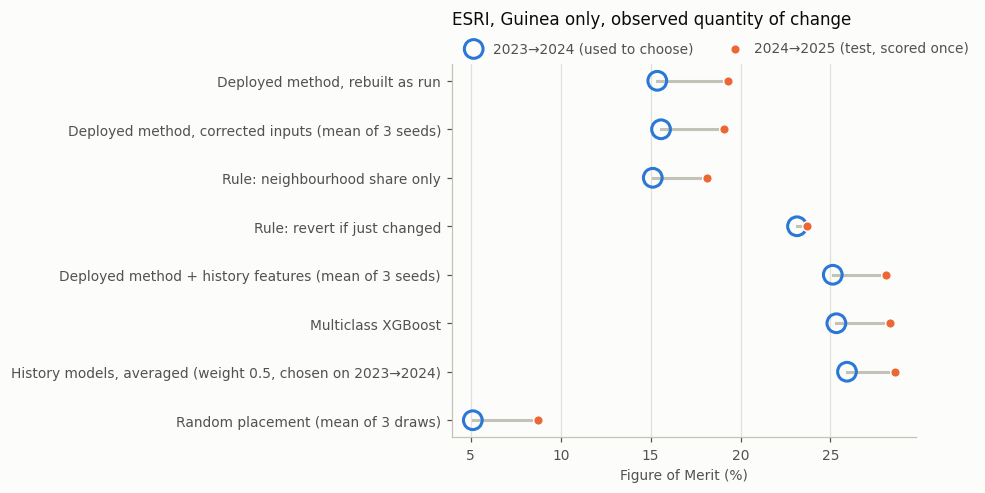

In [9]:
plot = summary.dropna(subset=["Choose: 2023→2024 FoM %"]).rename(columns={"Choose: 2023→2024 FoM %": "a", "Test: 2024→2025 FoM %": "b"})
H.plot_dumbbell(plot, "ESRI, Guinea only, observed quantity of change", left="a", right="b",
                labels=("2023→2024 (used to choose)", "2024→2025 (test, scored once)"),
                xlabel="Figure of Merit (%)")
plt.tight_layout(); plt.show()

On the metric, the improvement approach carries over strongly: **+9.0 points from history
features alone, +9.5 with averaging**, the same ~28% as on MODIS, and stable
across seeds and between the two years. The next section shows what those
extra points are made of.

## 6 · What the gain is made of: label flicker

ESRI's annual maps reclassify a large share of pixels back and forth between
similar classes (mostly Trees ↔ Rangeland), the instability §8 of the document
already flags. Every pixel that flips is scored as "change" by the Figure of Merit.

In [10]:
prof = E.grid(); g = H.guinea_mask(prof)
maps = {y: E.esri_cached(y) for y in range(2017, 2026)}
ok3 = lambda a, b, c: g & E.valid_classes(a, b, c)
rows = []
for y in range(2018, 2025):
    ok = ok3(maps[y - 1], maps[y], maps[y + 1]); ch = ok & (maps[y - 1] != maps[y])
    rows.append((f"{y - 1}→{y}", int(ch.sum()), 100 * (ch & (maps[y + 1] == maps[y - 1])).sum() / ch.sum()))
flicker = pd.DataFrame(rows, columns=["Changes in", "Changed pixels (Guinea)", "% back to the earlier class one year later"])
H.show(flicker, 1)

Changes in,Changed pixels (Guinea),% back to the earlier class one year later
2017→2018,588827,25.2
2018→2019,452196,38.8
2019→2020,436255,31.9
2020→2021,389090,38.1
2021→2022,419704,35.4
2022→2023,414327,38.0
2023→2024,428403,41.6


In [11]:
a, b, c = maps[2023], maps[2024], maps[2025]
ok = ok3(a, b, c); obs = ok & (c != b)
seen = np.any(E._past(2024) == c[None], axis=0)      # every earlier map, 2017-2023
kinds = {"Back to its 2023 class": obs & (c == a), "Back to a class held 2017–2022": obs & seen & (c != a),
         "To a class not held since 2017 (new)": obs & ~seen}
print("Observed change 2024→2025:", f"{obs.sum():,} px")
for k, m_ in kinds.items():
    print(f"   {k:40s} {m_.sum():>8,}  ({100 * m_.sum() / obs.sum():.1f}%)")

def sim(tag, mode, sub="allocation"):
    return H.read_tif(E.RUNS / tag / "test" / sub / mode.replace(" ", "_") / "predicted_land_cover.tif")[0]
models = {"Deployed method (reference)": sim("R0c_guinea_dated", "Expander-only"),
          "Deployed method + history features": sim("R2_history", "Expander-only"),
          "Multiclass XGBoost": sim("R3_multiclass_xgb", "Multiclass XGBoost"),
          "History models, averaged": sim("R4_average", f"w={best_w}", f"allocation_w{best_w}"),
          "Rule: revert if just changed": E.rule_maps(2023, 2024)["Revert to the 2023 class if changed 2023->2024"]}
rows = []
for name, s in models.items():
    hit = obs & (s == c) & (s != b)
    rows.append((name, int(hit.sum()), *[int((hit & km).sum()) for km in kinds.values()],
                 100 * (hit & kinds["To a class not held since 2017 (new)"]).sum() / kinds["To a class not held since 2017 (new)"].sum()))
hits = pd.DataFrame(rows, columns=["Configuration", "Hits", *kinds.keys(), "% of new change found"])
H.show(hits, 1)

Observed change 2024→2025: 507,539 px
   Back to its 2023 class                    178,230  (35.1%)
   Back to a class held 2017–2022            235,635  (46.4%)
   To a class not held since 2017 (new)       93,674  (18.5%)


Configuration,Hits,Back to its 2023 class,Back to a class held 2017–2022,To a class not held since 2017 (new),% of new change found
Deployed method (reference),160437,62971,78043,19423,20.7
Deployed method + history features,219496,133033,81953,4510,4.8
Multiclass XGBoost,221110,142924,74217,3969,4.2
"History models, averaged",222892,140091,78822,3979,4.2
Rule: revert if just changed,178230,178230,0,0,0.0


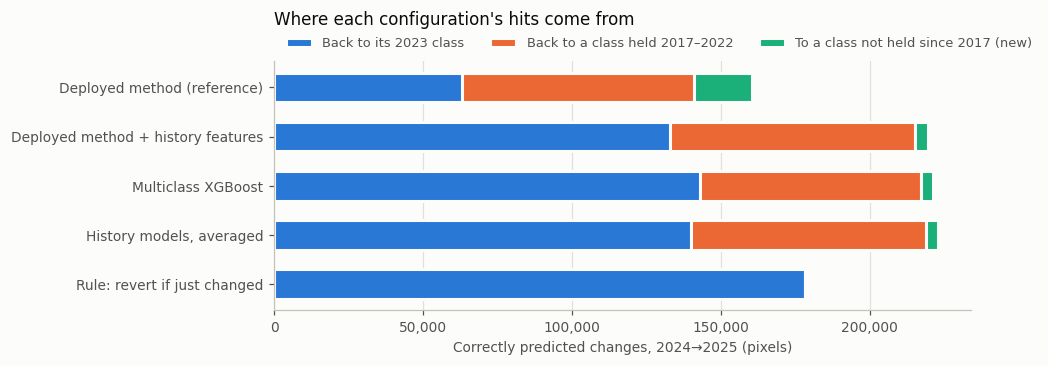

In [12]:
fig, ax = plt.subplots(figsize=(9, 3.4))
data = hits.iloc[::-1]
left = np.zeros(len(data))
for colour, k in zip(H.SERIES, kinds):
    ax.barh(data["Configuration"], data[k], left=left, color=colour, height=0.6, label=k,
            edgecolor=H.SURFACE, linewidth=2)
    left += data[k].to_numpy()
H.style_axes(ax)
ax.set_xlabel("Correctly predicted changes, 2024→2025 (pixels)", color=H.INK_2)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:,.0f}"))
ax.set_title("Where each configuration's hits come from", loc="left", color=H.INK, fontsize=11, pad=24)
ax.legend(frameon=False, fontsize=8.5, ncol=3, loc="lower left", bbox_to_anchor=(0, 1.0), labelcolor=H.INK_2)
plt.tight_layout(); plt.show()

### On the map

The same 2024→2025 forecasts, pixel by pixel: the deployed method (seed 42)
and the averaged history models. Two 40 km windows are picked from the **observed**
map only, inside Guinea: window 1 has the most change of any kind, window 2 the
most genuinely new change.

In [13]:
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch
prof = E.grid(); g = H.guinea_mask(prof)
b, c = E.esri_cached(2024), E.esri_cached(2025)
ok = g & E.valid_classes(b, c)
held = np.any(E._past(2024) == c[None], axis=0)
new_change = ok & (b != c) & ~held

def test_map(tag, mode, sub="allocation"):
    return H.read_tif(E.RUNS / tag / "test" / sub / mode.replace(" ", "_") / "predicted_land_cover.tif")[0]
forecasts = {"Deployed method": test_map("R0c_guinea_dated", "Expander-only"),
             "History models": test_map("R4_average", f"w={best_w}", f"allocation_w{best_w}")}
codes = {k: H.outcome_map(b, c, s, ok & E.valid_classes(s)) for k, s in forecasts.items()}

# Two 40 km windows, fully inside Guinea, picked from the observed map only
windows = {"1": H.busiest_window(ok & (b != c), inside=g), "2": H.busiest_window(new_change, inside=g)}
for k, w in windows.items():
    what = "most change of any kind" if k == "1" else "most genuinely new change"
    print(f"Window {k} ({what}): {H.window_label(w, prof)}")

Window 1 (most change of any kind): 40 km window centred 8.90°N, 8.72°W
Window 2 (most genuinely new change): 40 km window centred 8.90°N, 8.36°W


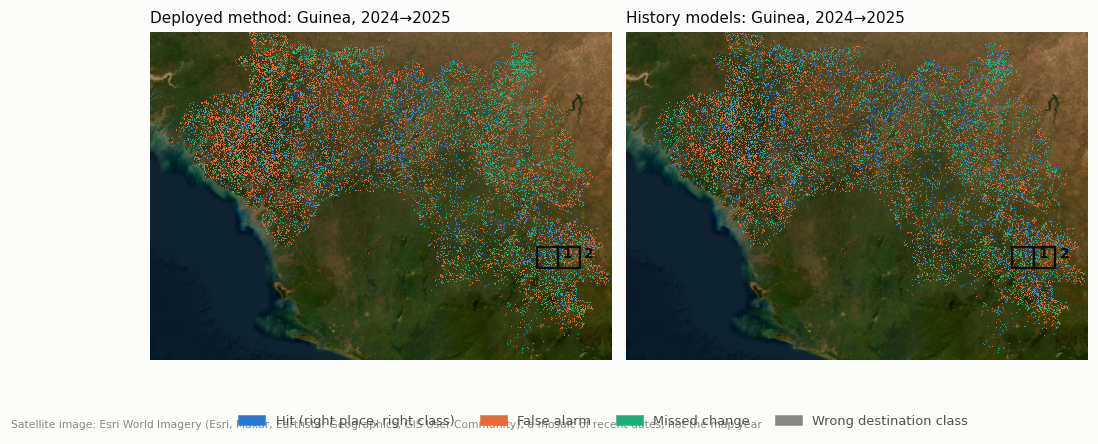

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.3), gridspec_kw={"wspace": 0.03})
for ax, (name, cd) in zip(axes, codes.items()):
    H.plot_outcome_map(cd, f"{name}: Guinea, 2024→2025", ax, legend=False, profile=prof)
    for k, w in windows.items():
        H.mark_window(ax, w, k)
H.outcome_legend(fig, satellite=True, loc="lower center", bbox_to_anchor=(0.5, -0.02))
plt.show()

At national scale the two forecasts look alike: errors are everywhere, and the
amount of change is the same by design (observed demand). Both windows lie side by
side in the south-east, around 8.9°N, 8.4–8.7°W. What kind of change happens there:

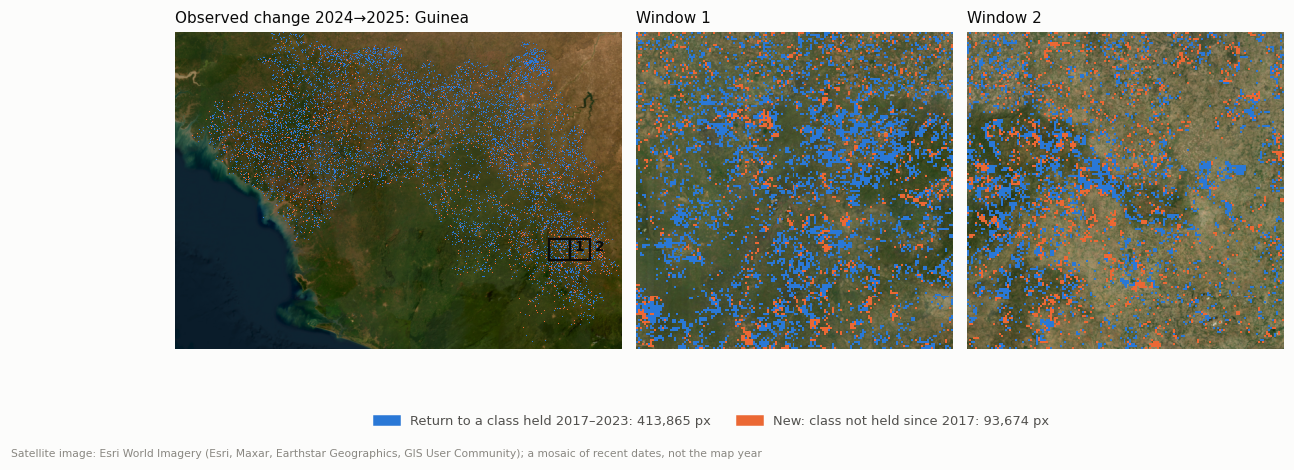

In [15]:
kind = np.zeros(b.shape, np.uint8); kind[ok] = 1
kind[ok & (b != c) & held] = 2; kind[new_change] = 3
cmap = ListedColormap(["#ffffff", H.NEUTRAL_FILL, H.SERIES[0], H.SERIES[1]])
fig, axes = plt.subplots(1, 3, figsize=(13, 4.4), gridspec_kw={"width_ratios": [1.41, 1, 1], "wspace": 0.04})
H.plot_satellite(axes[0], prof)
axes[0].imshow(np.ma.masked_less_equal(kind, 1), cmap=cmap, vmin=0, vmax=3, interpolation="nearest")
for k, w in windows.items():
    H.mark_window(axes[0], w, k)
for ax, (k, w) in zip(axes[1:], windows.items()):
    H.plot_satellite(ax, prof, w)
    ax.imshow(np.ma.masked_less_equal(H.crop(kind, w), 1), cmap=cmap, vmin=0, vmax=3, interpolation="nearest")
for ax, t in zip(axes, ("Observed change 2024→2025: Guinea", "Window 1", "Window 2")):
    ax.set_axis_off(); ax.set_title(t, loc="left", color=H.INK, fontsize=10)
fig.legend(handles=[Patch(color=H.SERIES[0], label=f"Return to a class held 2017–2023: {(kind == 2).sum():,} px"),
                    Patch(color=H.SERIES[1], label=f"New: class not held since 2017: {(kind == 3).sum():,} px")],
           loc="lower center", bbox_to_anchor=(0.5, -0.02), ncol=2, frameon=False, fontsize=8.5, labelcolor=H.INK_2)
H.satellite_credit(fig, -0.06)
plt.show()

Returns to an earlier class (blue) dominate everywhere. New change (orange) is
scattered, and denser in window 2. Zooming in on both windows:

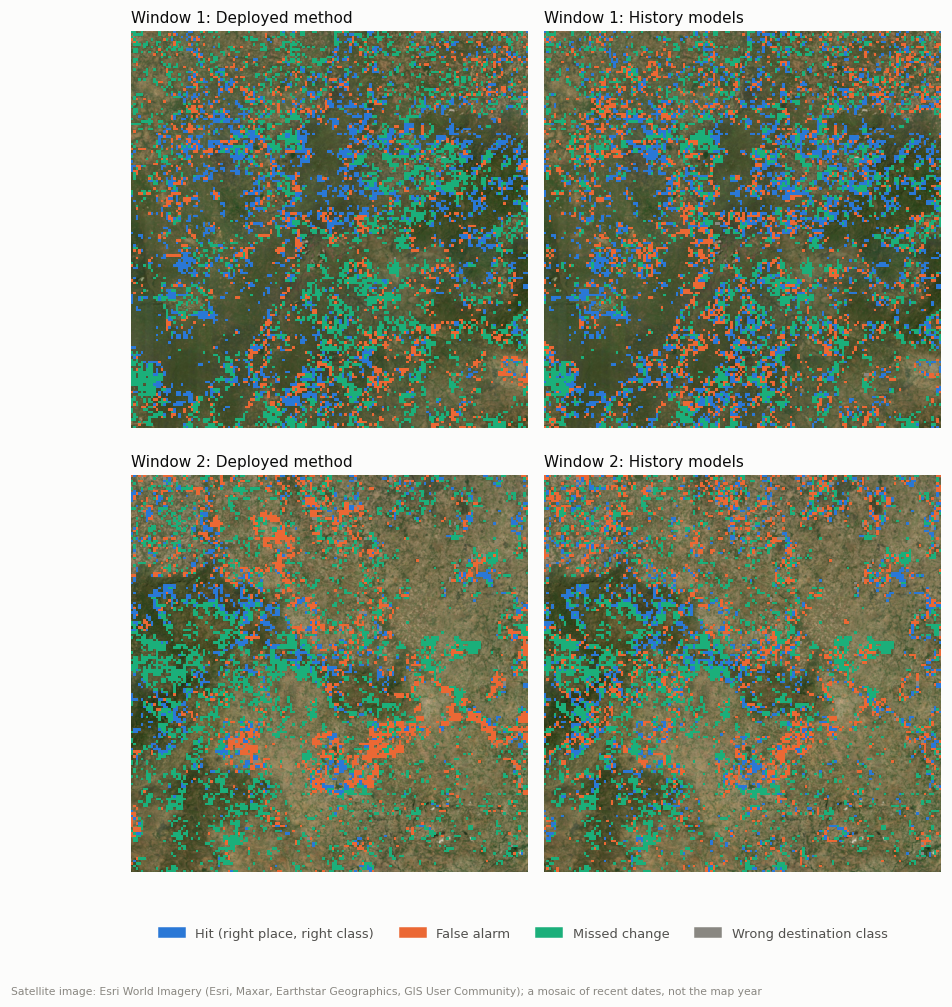

Window,Forecast,Hits,False alarms,Missed,Wrong class,New changes found,FoM % in window
1,Deployed method,2578,1727,3609,4,379,32.6
1,History models,3113,2419,3070,8,12,36.2
2,Deployed method,1185,1886,3593,132,309,17.4
2,History models,1551,1964,3203,156,142,22.6


In [16]:
fig, axes = plt.subplots(2, 2, figsize=(9.5, 10), gridspec_kw={"wspace": 0.04, "hspace": 0.1})
rows = []
for i, (k, w) in enumerate(windows.items()):
    for j, (name, cd) in enumerate(codes.items()):
        z = H.crop(cd, w)
        H.plot_outcome_map(z, f"Window {k}: {name}", axes[i, j], legend=False, profile=prof, window=w)
        rows.append({"Window": k, "Forecast": name, "Hits": int((z == 2).sum()), "False alarms": int((z == 3).sum()),
                     "Missed": int((z == 4).sum()), "Wrong class": int((z == 5).sum()),
                     "New changes found": int(H.crop(new_change & (forecasts[name] == c), w).sum()),
                     "FoM % in window": 100 * (z == 2).sum() / max(np.isin(z, (2, 3, 4, 5)).sum(), 1)})
H.outcome_legend(fig, satellite=True, loc="lower center", bbox_to_anchor=(0.5, 0.04))
plt.show()
window_scores = pd.DataFrame(rows)
H.show(window_scores, 1)

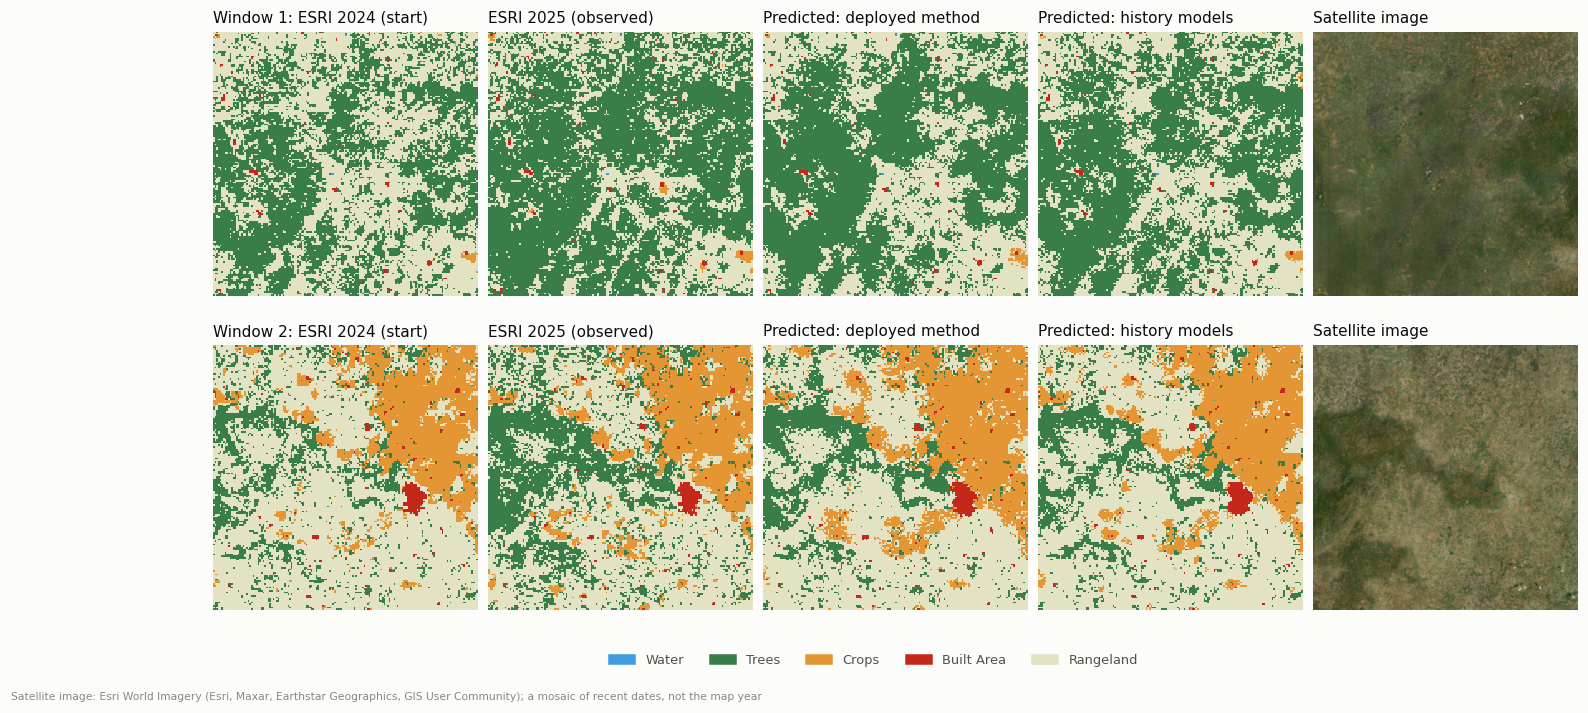

In [17]:
fig, axes = plt.subplots(2, 5, figsize=(16, 7), gridspec_kw={"wspace": 0.04, "hspace": 0.12})
panels = {"ESRI 2024 (start)": b, "ESRI 2025 (observed)": c,
          **{f"Predicted: {k.lower()}": v for k, v in forecasts.items()}}
present = set()
for i, (k, w) in enumerate(windows.items()):
    for j, (title, lc) in enumerate(panels.items()):
        H.plot_classes(H.crop(lc, w), f"Window {k}: {title}" if j == 0 else title, axes[i, j], H.crop(g, w))
        present |= set(np.unique(H.crop(lc, w)).tolist())
    H.plot_satellite(axes[i, 4], prof, w, title="Satellite image")
H.esri_class_legend(fig, present, loc="lower center", bbox_to_anchor=(0.5, 0.03))
H.satellite_credit(fig)
plt.show()

* **Window 1 (most change):** the history models score higher on all change (36.2% against
  32.6%). In the land-cover panels, their forecast copies the speckled Trees/Rangeland mosaic
  of the ESRI maps, which is where flicker happens. But the deployed method finds 379 new
  changes in the window, the history models 12.
* **Window 2 (most new change):** the history models again score higher on all change (22.6%
  against 17.4%), but the deployed method finds more than twice as many new changes (309
  against 142). It grows existing patches into compact areas (the Expander's neighbourhood
  logic). That misses flicker, but finds more of the change that is new.
* The windows show the national result in miniature: the history models win on returns, the deployed
  method on new change.

**Reading this:**

* **Most of what the metric counts as change is flicker.** Between 25% and 42%
  of each year's changes revert the next year, and 82% of the 2024→2025 changes put
  a pixel back into a class it held at some point since 2017.
* **The history-based models score higher by predicting flicker.** 98% of their hits
  are returns to an earlier class. The deployed method's figure is 88%.
* **They find far less genuinely new change.** For change into a class the pixel had
  not held since 2017, the deployed method finds ~21% of it. The history models
  find ~4–5%, about 80% fewer.

## 7 · The flip-back check

The score stays the Figure of Merit over all change, the measure every published comparison of
land-change models and every tool uses (Pontius et al. 2008). But section 6 shows a weakness of
ESRI's annual maps: 82% of the observed change puts a pixel back into a class it held before,
mostly Trees ↔ Rangeland, and tree canopy cannot regrow within one year. Deforestation is
also defined as a conversion of land use, not a temporary loss (FAO 2020). A model can raise
the score by predicting these flips without forecasting any land change.

So every addition gets one extra check: **an addition must not find less genuinely new change than the deployed method.**

* A change, observed or predicted, is **new** when its destination class does not appear in
  any of the pixel's earlier ESRI maps (2017 up to the year before the forecast start). That is
  the whole ESRI record, so there is no time window to tune; 3- and 5-year windows give the same
  ranking (below). Otherwise it is a **return**, what Pontius et al. (2017) call alternation.
* **New-change FoM** = correctly predicted new changes ÷ pixels with an observed *or* a
  predicted new change (`E.change_kind_scores`): the same formula as the score, over new change only.
* **New change found** = the share of observed new change predicted correctly.

It uses only maps from before the forecast start, so it never looks at the future. Each
forecast is again compared with random placement of the same amount of change (`E.random_like`).

**How the score splits.** For the deployed method (seed 42) on 2024→2025:

| Part of the change | Observed pixels | FoM |
|---|---:|---:|
| Returns to a class held since 2017 | 413,865 | 24.1% |
| New: into a class not held since 2017 | 93,674 | 7.4% |
| **All change (the score)** | 507,539 | **19.1%** |

The score sits between the two parts. Returns are easy to predict from a pixel's own past;
new change has no earlier state to return to, so the model has to recognise conditions, not memory.

In [18]:
def candidates(ph):
    t_prev, t_start, _ = E.phase_years(ph)
    rm = E.rule_maps(t_prev, t_start)
    alloc = lambda tag, mode, sub="allocation": H.read_tif(
        E.RUNS / tag / ph / sub / mode.replace(" ", "_") / "predicted_land_cover.tif")[0]
    return {"Deployed method, rebuilt as run": [alloc("R0a_deployed_replica", "Expander-only")],
            "Deployed method, corrected inputs (mean of 3 seeds)": [alloc(t, "Expander-only") for t in seeds.values()],
            "Rule: eight-neighbour majority": [rm["Eight-neighbour majority"]],
            "Rule: revert if just changed": [rm[next(k for k in rm if k.startswith("Revert"))]],
            "Rule: neighbourhood share only": [alloc("R1_model_free", "Neighbourhood share only (deployed allocator)")],
            "Deployed method + history features (mean of 3 seeds)": [alloc(t, "Expander-only")
                for t in ("R2_history", "R2_history_seed1", "R2_history_seed2")],
            "Multiclass XGBoost": [alloc("R3_multiclass_xgb", "Multiclass XGBoost")],
            "History models, averaged": [alloc("R4_average", f"w={best_w}", f"allocation_w{best_w}")]}

REF, RANDOM = "Deployed method, corrected inputs (mean of 3 seeds)", "Random placement (mean of 3 draws)"
rows = []
for ph in PH:
    _, t_start, t_fore = E.phase_years(ph)
    start, observed = E.esri_cached(t_start), E.esri_cached(t_fore)
    sims = candidates(ph)
    # Floor: the deployed method's own number of each transition, placed at random
    ok_ = g & E.valid_classes(start, observed, sims[REF][0])
    sims[RANDOM] = [E.random_like(start, sims[REF][0], ok_, seed=s) for s in range(3)]
    if ph == "test":
        test_sims = sims
    for name, maps_ in sims.items():
        sc = [E.change_kind_scores(t_start, observed, s, g)["new"] for s in maps_]
        new = [x["FoM"] for x in sc]
        rows.append((name, ph, np.mean(new), (max(new) - min(new)) / 2 if len(new) > 1 else np.nan,
                     np.mean([x["found_pct"] for x in sc]), np.mean([x["predicted"] for x in sc]), sc[0]["observed"]))
long = pd.DataFrame(rows, columns=["Configuration", "phase", "fom", "spread", "found", "predicted", "observed"])
pick = lambda ph, col: long[long.phase == ph].set_index("Configuration")[col]
scores = pd.DataFrame({"New-change FoM % 2023→2024": pick("validation", "fom"),
                       "New-change FoM % 2024→2025": pick("test", "fom"),
                       "± across seeds (2024→2025)": pick("test", "spread"),
                       "New change found % 2024→2025": pick("test", "found"),
                       "New changes predicted 2024→2025": pick("test", "predicted").round(0).astype(int)}).reset_index()
scores["× random 2024→2025"] = scores["New-change FoM % 2024→2025"] / pick("test", "fom")[RANDOM]
print(f"Observed new change: {int(pick('validation', 'observed').iloc[0]):,} px (2023→2024), "
      f"{int(pick('test', 'observed').iloc[0]):,} px (2024→2025)")
H.show(scores)

Observed new change: 112,313 px (2023→2024), 93,674 px (2024→2025)


Configuration,New-change FoM % 2023→2024,New-change FoM % 2024→2025,± across seeds (2024→2025),New change found % 2024→2025,New changes predicted 2024→2025,× random 2024→2025
"Deployed method, rebuilt as run",8.94,7.81,,21.01,178759,2.72
"Deployed method, corrected inputs (mean of 3 seeds)",8.84,7.39,0.06,20.60,187471,2.57
Rule: eight-neighbour majority,6.24,5.98,,22.45,280422,2.08
Rule: revert if just changed,0.00,0.00,,0.00,0,0.00
Rule: neighbourhood share only,8.26,6.87,,19.52,191581,2.39
Deployed method + history features (mean of 3 seeds),5.96,3.54,0.19,4.49,29683,1.23
Multiclass XGBoost,5.03,3.30,,4.24,30687,1.15
"History models, averaged",5.45,3.44,,4.25,26275,1.20
Random placement (mean of 3 draws),2.67,2.88,0.02,11.79,303548,1.00


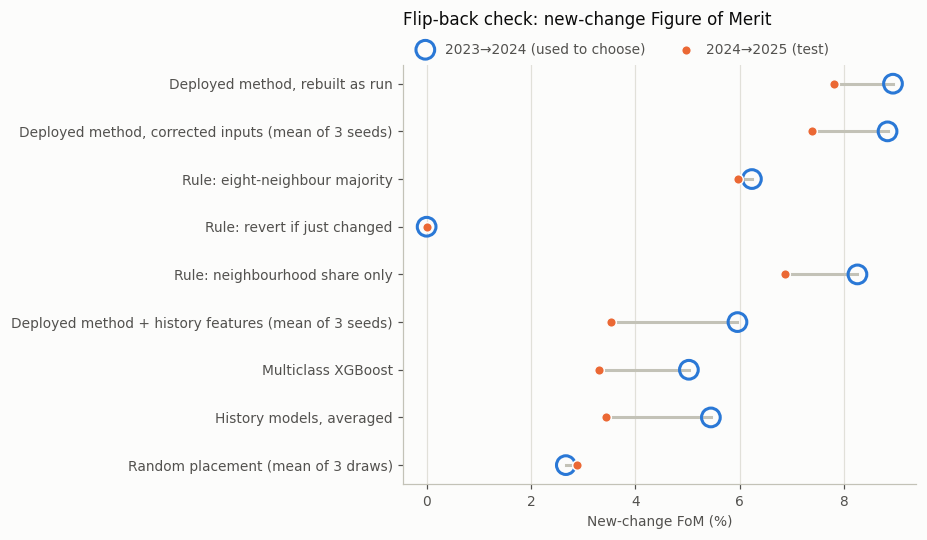

In [19]:
plot = scores.rename(columns={"New-change FoM % 2023→2024": "a", "New-change FoM % 2024→2025": "b"})
H.plot_dumbbell(plot, "Flip-back check: new-change Figure of Merit", left="a", right="b",
                labels=("2023→2024 (used to choose)", "2024→2025 (test)"), xlabel="New-change FoM (%)")
plt.tight_layout(); plt.show()

**Reading this:**

* **The deployed method (corrected inputs) is the best model on new change in both years:**
  8.8% and 7.4%, 2.6 times random placement on 2024→2025. The neighbourhood-only rule
  comes next (6.9%), so the deployed predictors add about half a point over neighbourhood alone.
* **The rebuild as run scores 0.4 points higher on 2024→2025** (7.8%). It used vegetation and
  rainfall measured after the forecast start (section 1b), so the corrected version is the
  honest score.
* **The history models barely beat random placement** (3.3–3.5% against 2.9%). Given the
  observed number of each transition, they place it almost entirely on pixels returning
  to an earlier class: about 30,000 new changes predicted against 93,674 observed.
* **The revert rule scores exactly 0**, by construction. On the document's metric it scored
  23.7%, above the deployed method: the clearest sign of why the check is needed: the
  all-change figure alone cannot tell flicker-chasing from real forecasting.

**Does the definition of "new" matter?** Pontius et al. (2017) define returns over the
whole series, which is what is used here. The same forecasts scored with shorter memories:

In [20]:
_, t_start, t_fore = E.phase_years("test")
observed = E.esri_cached(t_fore)
check = [REF, "Rule: neighbourhood share only", "Deployed method + history features (mean of 3 seeds)",
         "History models, averaged", RANDOM]
definitions = {"Not held in the last 3 years": 3, "Not held in the last 5 years": 5, "Not held since 2017 (used)": None}
window_check = pd.DataFrame({d: [np.mean([E.change_kind_scores(t_start, observed, s, g, window=w)["new"]["FoM"]
                                          for s in test_sims[n]]) for n in check]
                             for d, w in definitions.items()}, index=check)
print("New-change FoM % on 2024→2025, for three definitions of 'new':")
H.show(window_check.reset_index(names="Configuration"))

New-change FoM % on 2024→2025, for three definitions of 'new':


Configuration,Not held in the last 3 years,Not held in the last 5 years,Not held since 2017 (used)
"Deployed method, corrected inputs (mean of 3 seeds)",12.06,10.26,7.39
Rule: neighbourhood share only,10.64,9.16,6.87
Deployed method + history features (mean of 3 seeds),8.81,3.72,3.54
"History models, averaged",8.33,3.45,3.44
Random placement (mean of 3 draws),5.05,4.31,2.88


The ranking is the same under all three definitions: the deployed method first, then the
neighbourhood rule, the history models and random placement. Only the level changes,
because a stricter definition leaves fewer, harder changes.

**At what scale is the forecast useful?** Pontius et al. (2004) compare a forecast with the
reference at coarser and coarser resolutions: at each cell size, the agreement is the
smaller of the observed and predicted amounts of each change in the cell
(`E.fom_by_resolution`).

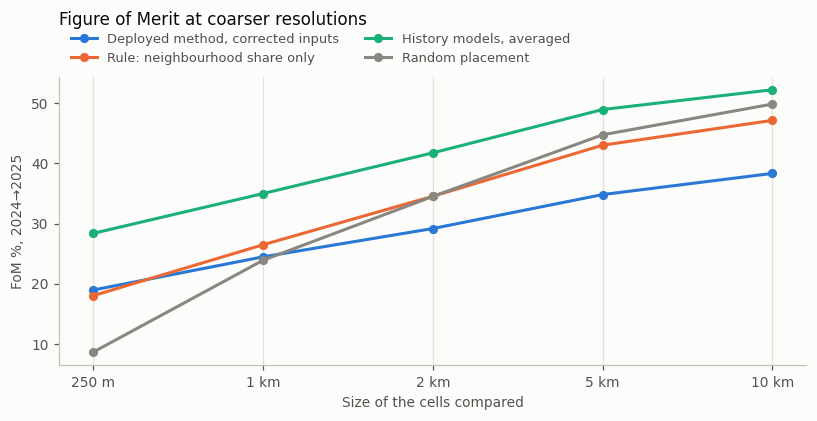

In [21]:
km = {1: "250 m", 4: "1 km", 8: "2 km", 20: "5 km", 40: "10 km"}
resolution = pd.DataFrame({n: pd.DataFrame([E.fom_by_resolution(E.esri_cached(t_start), observed, s, g, tuple(km))
                                            for s in test_sims[n]]).mean()
                           for n in [REF, "Rule: neighbourhood share only", "History models, averaged", RANDOM]}).T
resolution.columns = list(km.values())
H.show(resolution.reset_index(names="Configuration"))

fig, ax = plt.subplots(figsize=(7.5, 3.9))
for colour, n in zip(H.SERIES + [H.MUTED], resolution.index):
    ax.plot(resolution.columns, resolution.loc[n], color=colour, linewidth=2, marker="o", markersize=5,
            label=n.split(" (")[0])
H.style_axes(ax)
ax.set_xlabel("Size of the cells compared", color=H.INK_2)
ax.set_ylabel("FoM %, 2024→2025", color=H.INK_2)
ax.set_title("Figure of Merit at coarser resolutions", loc="left", color=H.INK, fontsize=11, pad=34)
ax.legend(frameon=False, fontsize=8.5, ncol=2, loc="lower left", bbox_to_anchor=(0, 1.0), labelcolor=H.INK_2)
plt.tight_layout(); plt.show()

* **The deployed method beats random placement at 250 m (2.2 times) and still at 1 km**
  (24.5% against 23.9%). From 2 km on, random placement scores higher (34.5% against 29.2%).
* So the deployed method puts change on the right pixels within a neighbourhood, but not in
  the right regions: its regional pattern is no better than spreading the change evenly.
  Pontius et al. (2004) call the cell size at which a model stops beating its null comparison
  the *null resolution*. Against random placement it lies between 1 and 2 km.
* The neighbourhood rule keeps up with random placement to 2 km, so where classes already are
  carries some regional information. That is the idea notebook 08 tests.
* The history models stay above random placement at every size, by placing returns where
  earlier change happened.

## Summary

| On 2024→2025 (test) | Figure of Merit | × random | Flip-back check: new change found |
|---|---:|---:|---:|
| **Deployed method, corrected inputs** (mean of 3 seeds) | **19.1%** | **2.2** | **21%** |
| Rule: neighbourhood share only | 18.1% | 2.1 | 20% |
| Rule: revert if just changed (its own amount of change) | 23.7% | – | 0% |
| Deployed method + history features (mean of 3 seeds) | 28.1% | 3.2 | 4% |
| History models, averaged | 28.6% | 3.3 | 4% |
| Random placement | 8.7% | 1.0 | 12% |

* **The improvement approach raises the score by 9.5 points (section 5), but fails the
  flip-back check.** 98% of its correct predictions are pixels going back to an earlier class,
  and it finds about 80% less genuinely new change than the deployed method.
* **The deployed method, with corrected inputs, is the reference to beat:** 15.6% on
  2023→2024 and 19.1% on 2024→2025.
* **Its weakness is regional:** it places change well locally but not by region
  (null resolution 1–2 km).

**Rule from here** (README): a configuration improves on the deployed method when, chosen on
2023→2024 only, its Figure of Merit on 2024→2025 is higher by more than the spread across
seeds (±0.05), it beats random placement (Pontius et al. 2004; Bouthillier et al. 2021), and it
passes the flip-back check: its new-change FoM is not lower than the deployed method's.

<small>
Bouthillier, X., et al. (2021). Accounting for variance in machine learning benchmarks. *Proceedings of Machine Learning and Systems* 3.<br>
FAO (2020). Global Forest Resources Assessment 2020: Terms and definitions. Forest Resources Assessment Working Paper 188. Rome.<br>
Pontius, R.G. Jr., Huffaker, D., Denman, K. (2004). Useful techniques of validation for spatially explicit land-change models. *Ecological Modelling* 179(4), 445–461.<br>
Pontius, R.G. Jr., Boersma, W., Castella, J.-C., et al. (2008). Comparing the input, output, and validation maps for several models of land change. *Annals of Regional Science* 42(1), 11–37.<br>
Pontius, R.G. Jr., Krithivasan, R., Sauls, L., Yan, Y., Zhang, Y. (2017). Methods to summarize change among land categories across time intervals. *Journal of Land Use Science* 12(4), 218–230.
</small>

In [22]:
H.SUMMARY.mkdir(parents=True, exist_ok=True)
for frame, name in [(labels, "06_predictor_labels"), (reference, "06_reference_rows"), (noise, "06_seed_noise"),
                    (rules, "06_model_free"), (weights, "06_r4_weights"), (summary, "06_summary"),
                    (flicker, "06_flicker"), (hits, "06_hits_by_kind"), (scores, "06_new_change_fom"), (window_check, "06_window_check"), (resolution, "06_resolution"), (window_scores, "06_window_scores")]:
    frame.to_csv(H.SUMMARY / f"{name}.csv", index=False)
print("Saved tables to", H.SUMMARY.relative_to(H.ROOT))

Saved tables to outputs\summary
